<a href="https://colab.research.google.com/github/romanotancredi/equity-investment-research-portfolio/blob/main/03_performance_and_risk_analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Phase 3 — Performance & Risk Analytics

This notebook evaluates the historical return and risk
characteristics of a hypothetical global equity portfolio.

* Portfolio: 60% VTI, 30% VEA, 10% VW
* Benchmark: VT
* Currency: USD
* Rebalancing: Daily
* Risk-free rate: 3-Month T-Bill rate

In [13]:

# ---------------------------------------------------------
# PHASE 3 - STEP 1: LOAD DATA AND RECONSTRUCT THE PORTFOLIO
# ---------------------------------------------------------

# Import pandas to work with tabular financial data.
import pandas as pd

# Import numpy for numerical and statistical calculations.
import numpy as np

# Import matplotlib to visualise our performance and risk.
import matplotlib.pyplot as plt


# Define the location of the shared CSV file on GitHub.
# This ensures every notebook uses the same market data.

data_url = (
    "https://raw.githubusercontent.com/romanotancredi/"
    "equity-investment-research-portfolio/refs/heads/main/"
    "01-equity-performance-and-risk/data/etf_prices.csv"
)

# Load the CSV into a DataFrame.
#
# index_col="Date" uses the Date column as the index.
# parse_dates converts strings into datetime objects.

prices = pd.read_csv(
    data_url,
    index_col="Date",
    parse_dates=["Date"]
)

# Keep the ETFs in a consistent order.
prices = prices[["VTI", "VEA", "VWO", "VT"]].sort_index()

# Remove observations with missing data.
prices = prices.dropna()

# pct_change() calculates daily simple returns.
# The first row has no previous observation, so drop it.

daily_returns = prices.pct_change().dropna()

# Define our hypothetical portfolio weights.
#
# These weights are held constant every day,
# implying daily portfolio rebalancing.

weights = pd.Series({
    "VTI": 0.60,
    "VEA": 0.30,
    "VWO": 0.10
})

# Verify weights sum to 100%.
assert np.isclose(weights.sum(), 1.0)

# Calculate the weighted sum of ETF returns using dot().
portfolio_returns = daily_returns[weights.index].dot(weights)

# Extract benchmark returns.
benchmark_returns = daily_returns["VT"]

# Combine both return series in one DataFrame.
performance = pd.DataFrame({
    "Portfolio": portfolio_returns,
    "Benchmark": benchmark_returns
})

# Calculate daily active returns.
performance["Active Return"] = (
    performance["Portfolio"] - performance["Benchmark"]
)

# Define the assumed number of trading days in a year.
trading_days = 252

# Display initial observations to validate our calculations.
display(performance.head())


,Portfolio,Benchmark,Active Return
Date,,,
2020-01-03,-0.009245,-0.009045,-0.000199
2020-01-06,0.002897,0.003701,-0.000805
2020-01-07,-0.001944,-0.003073,0.001128
2020-01-08,0.003819,0.004068,-0.000248
2020-01-09,0.005487,0.004911,0.000576


In [14]:

# ---------------------------------------------------------
# PHASE 3 - STEP 2: ANNUALISED COMPOUNDED RETURNS
# ---------------------------------------------------------

# Select only the Portfolio and Benchmark return columns.
# We exclude Active Return because daily return differences
# are not a directly investable return series.

asset_returns = performance[["Portfolio", "Benchmark"]]

# Count the number of daily return observations.
#
# len() gives us the number of rows in our dataset.

number_of_days = len(asset_returns)

# Calculate the cumulative growth factor.
#
# (1 + returns) converts each return into a growth factor.
# prod() multiplies all growth factors together.

total_growth = (1 + asset_returns).prod()

# Convert cumulative growth into a compound annual rate.
#
# 252 / number_of_days scales the observed growth
# to an approximate 252-trading-day year.

annualised_returns = (
    total_growth ** (trading_days / number_of_days)
) - 1

# Calculate annualised geometric relative performance.
#
# This is different from subtracting the two CAGRs.

geometric_relative_return = (
    (1 + annualised_returns["Portfolio"])
    / (1 + annualised_returns["Benchmark"])
) - 1

# Display the results as percentages.

print("Annualised returns:")

display((annualised_returns * 100).round(2))

print(
    "Annualised geometric relative return:",
    round(geometric_relative_return * 100, 2),
    "%"
)


Annualised returns:


,0
Portfolio,12.26
Benchmark,12.00


Annualised geometric relative return: 0.24 %


In [15]:

# ---------------------------------------------------------
# PHASE 3 - STEP 3: ANNUALISED VOLATILITY
# ---------------------------------------------------------

# std() calculates the standard deviation of daily returns.
#
# ddof=1 means we use the sample standard deviation.
# This divides by N-1 rather than N.

daily_volatility = asset_returns.std(ddof=1)

# Annualise volatility using the square root of time.
#
# np.sqrt(252) calculates the square root of 252.
#
# This assumes daily returns are sufficiently independent
# for square-root-of-time scaling to be appropriate.

annualised_volatility = (
    daily_volatility * np.sqrt(trading_days)
)

print("Annualised Volatility (%):")

display((annualised_volatility * 100).round(2))


Annualised Volatility (%):


,0
Portfolio,19.23
Benchmark,19.19


In [16]:


# ---------------------------------------------------------
# PHASE 3 - STEP 4A: LOAD HISTORICAL US T-BILL RATES
# ---------------------------------------------------------

# Define the FRED CSV download URL.
# DTB3 contains daily 3-month Treasury bill discount yields.

fred_url = (
    "https://fred.stlouisfed.org/graph/fredgraph.csv"
    "?id=DTB3"
)

# Read the FRED dataset.
#
# index_col=0: Use the first column as the date index.
# parse_dates=[0]: Convert the first column into dates.
# na_values=["."]: Treat missing observations as NaN.

tbill = pd.read_csv(
    fred_url,
    index_col=0,
    parse_dates=[0],
    na_values=["."]
)

# Convert quoted percentage yields into decimals.
#
# Example: 4.50% becomes 0.045.

tbill["Discount Yield"] = tbill["DTB3"] / 100

# Convert the bank discount yield to an approximate
# annual investment yield using a 91-day maturity.
#
# T-bill discount quotes use a 360-day year.
# This approximation converts the quote to an
# annual simple yield using a 365-day convention.

days_to_maturity = 91

d = tbill["Discount Yield"]

tbill["Investment Yield"] = (
    365 * d / (360 - days_to_maturity * d)
)

# Remove dates with unavailable yield observations.
tbill = tbill.dropna(subset=["Investment Yield"])

# Match Treasury yields to our ETF trading dates.
#
# ffill() carries forward the latest available yield
# when no new observation is published.
#
# shift(1) uses the previous trading day's observed
# rate, avoiding same-day information being used
# to calculate that day's risk-free return.

aligned_yields = (
    tbill["Investment Yield"]
    .reindex(performance.index, method="ffill")
    .shift(1)
)

# Convert annual yields into approximate daily returns.
#
# Here we use a 252-trading-day compounding convention.
# A more precise cash-return model would account
# for actual calendar days between observations.

daily_risk_free = (1 + aligned_yields) ** (1 / 252) - 1

# Add risk-free returns to our performance dataset.

performance["Risk-Free Return"] = daily_risk_free

# Remove the initial observation if the lagged yield
# is unavailable. Then realign portfolio and benchmark.

performance = performance.dropna(
    subset=["Risk-Free Return"]
)

asset_returns = performance[["Portfolio", "Benchmark"]]

display(performance.head())



,Portfolio,Benchmark,Active Return,Risk-Free Return
Date,,,,
2020-01-06,0.002897,0.003701,-0.000805,0.000060
2020-01-07,-0.001944,-0.003073,0.001128,0.000061
2020-01-08,0.003819,0.004068,-0.000248,0.000061
2020-01-09,0.005487,0.004911,0.000576,0.000061
2020-01-10,-0.002265,-0.002077,-0.000189,0.000061


In [17]:

# ---------------------------------------------------------
# PHASE 3 - STEP 4B: HISTORICAL SHARPE RATIO
# ---------------------------------------------------------

# Calculate daily excess returns over the risk-free rate.
#
# sub(..., axis=0) subtracts the corresponding daily
# risk-free return from each portfolio/benchmark column.

excess_returns = asset_returns.sub(
    performance["Risk-Free Return"],
    axis=0
)

# Calculate the average daily excess returns.
average_excess_returns = excess_returns.mean()

# Calculate the standard deviation of daily portfolio
# and benchmark returns, using the sample convention.

daily_volatility = asset_returns.std(ddof=1)

# Calculate annualised Sharpe ratios.
#
# mean daily excess return * 252
# divided by daily volatility * sqrt(252)
#
# This simplifies to:
# mean daily excess / daily volatility * sqrt(252)

sharpe_ratios = (
    average_excess_returns
    / daily_volatility
    * np.sqrt(252)
)

print("Sharpe Ratios using historical US T-bill rates:")
display(sharpe_ratios.round(3))

Sharpe Ratios using historical US T-bill rates:


,0
Portfolio,0.556
Benchmark,0.544


In [18]:

# ---------------------------------------------------------
# PHASE 3 - STEP 5: TRACKING ERROR
# ---------------------------------------------------------

# Retrieve the daily active return series.
#
# Active Return = Portfolio Return - Benchmark Return

active_returns = performance["Active Return"]

# Calculate the standard deviation of daily active returns.
#
# This measures how much relative performance fluctuates.

daily_tracking_error = active_returns.std(ddof=1)

# Annualise tracking error.
#
# We use the same square-root-of-time convention
# previously applied to portfolio volatility.

annualised_tracking_error = (
    daily_tracking_error * np.sqrt(trading_days)
)

# Display tracking error as a percentage.

print(
    "Annualised Tracking Error:",
    round(annualised_tracking_error * 100, 2),
    "%"
)

Annualised Tracking Error: 0.89 %


In [19]:

# ---------------------------------------------------------
# PHASE 3 - STEP 6: INFORMATION RATIO
# ---------------------------------------------------------

# Calculate average daily active return.
#
# mean() returns the arithmetic average across observations.

average_daily_active_return = active_returns.mean()

# Annualise the average active return.
#
# Multiplying by 252 follows the arithmetic convention.
# This is not a compounded annual relative return.

annualised_arithmetic_active_return = (
    average_daily_active_return * trading_days
)

# Calculate Information Ratio.
#
# Numerator: annualised arithmetic active return
# Denominator: annualised tracking error

information_ratio = (
    annualised_arithmetic_active_return
    / annualised_tracking_error
)

print(
    "Annualised Arithmetic Active Return:",
    round(annualised_arithmetic_active_return * 100, 2),
    "%"
)

print(
    "Information Ratio:",
    round(information_ratio, 3)
)

Annualised Arithmetic Active Return: 0.25 %
Information Ratio: 0.276


In [20]:

# ---------------------------------------------------------
# PHASE 3 - STEP 7: MAXIMUM DRAWDOWN
# ---------------------------------------------------------

# Construct cumulative wealth indices starting at 100.
#
# cumprod() compounds daily returns over time.

wealth_index = (
    (1 + asset_returns).cumprod() * 100
)

# Add the initial investment value to the beginning.
#
# This ensures the first observation starts at 100,
# rather than after the first daily return.

initial_date = prices.index[0]

initial_values = pd.DataFrame(
    {"Portfolio": [100.0], "Benchmark": [100.0]},
    index=[initial_date]
)

wealth_index = pd.concat([initial_values, wealth_index])

# Calculate the running maximum value over time.
#
# cummax() stores the highest value reached up to
# each point in the historical series.

running_peak = wealth_index.cummax()

# Calculate drawdown from the previous peak.
#
# A value of -0.20 means the investment is 20%
# below its previous high.

drawdowns = wealth_index / running_peak - 1

# min() finds the largest negative drawdown.
max_drawdowns = drawdowns.min()

# idxmin() identifies the trough date.

max_drawdown_dates = drawdowns.idxmin()

print("Maximum Drawdowns (%):")

display((max_drawdowns * 100).round(2))

print("\nDrawdown Trough Dates:")

display(max_drawdown_dates)

Maximum Drawdowns (%):


,0
Portfolio,-34.35
Benchmark,-34.24



Drawdown Trough Dates:


,0
Portfolio,2020-03-23
Benchmark,2020-03-23


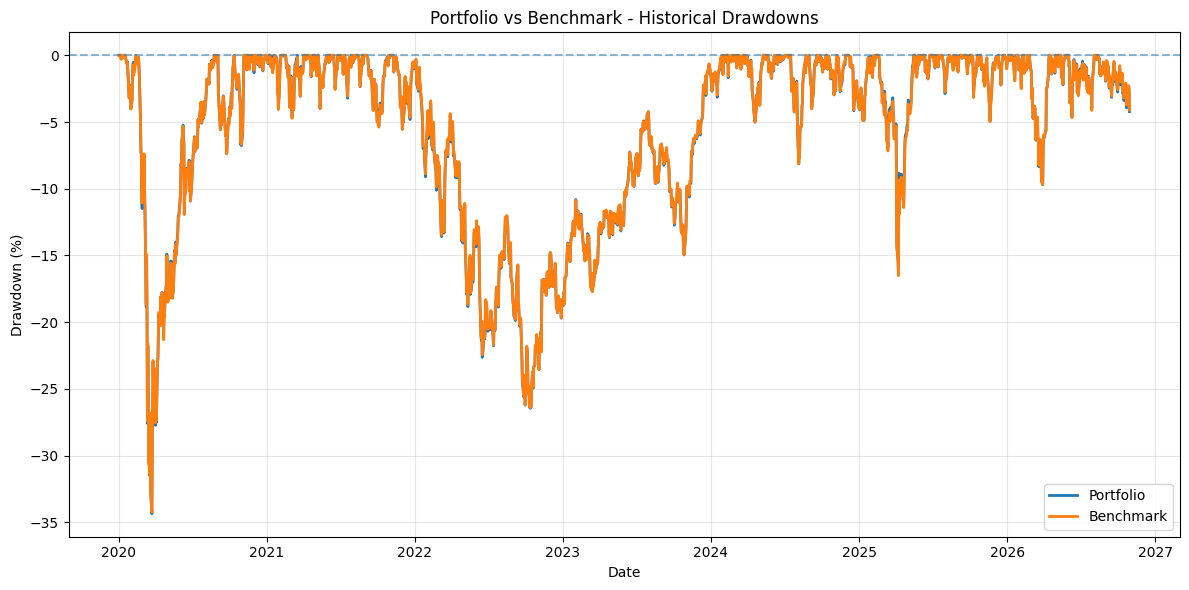

In [21]:

# ---------------------------------------------------------
# PHASE 3 - STEP 8: VISUALISE PORTFOLIO DRAWDOWNS
# ---------------------------------------------------------

# Create the chart.
plt.figure(figsize=(12, 6))

# Plot portfolio drawdowns as percentages.
plt.plot(
    drawdowns.index,
    drawdowns["Portfolio"] * 100,
    label="Portfolio",
    linewidth=2
)

# Plot benchmark drawdowns.
plt.plot(
    drawdowns.index,
    drawdowns["Benchmark"] * 100,
    label="Benchmark",
    linewidth=2
)

# Add a zero reference line representing no drawdown.
plt.axhline(0, linestyle="--", alpha=0.5)

# Add labels.
plt.title("Portfolio vs Benchmark - Historical Drawdowns")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")

# Format chart.
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Display.
plt.show()

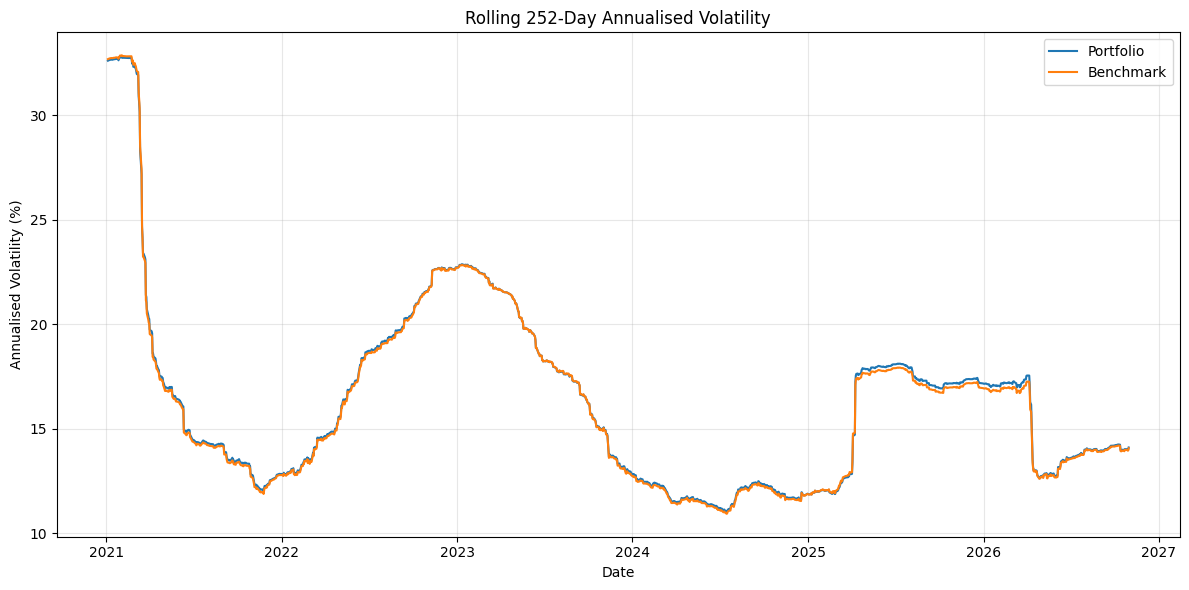

In [22]:

# ---------------------------------------------------------
# PHASE 3 - STEP 9: ROLLING ANNUALISED VOLATILITY
# ---------------------------------------------------------

# rolling(window=252) creates a moving window containing
# the most recent 252 daily return observations.
#
# std() calculates volatility within each window.
# The first 251 observations will be NaN because there
# are not yet enough observations for a full window.

rolling_volatility = (
    asset_returns
    .rolling(window=252)
    .std()
    * np.sqrt(trading_days)
)

# Plot the results as percentages.

plt.figure(figsize=(12, 6))

for column in rolling_volatility.columns:
    plt.plot(
        rolling_volatility.index,
        rolling_volatility[column] * 100,
        label=column
    )

plt.title("Rolling 252-Day Annualised Volatility")
plt.xlabel("Date")
plt.ylabel("Annualised Volatility (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:

# ---------------------------------------------------------
# PHASE 3 - STEP 10: BUILD PERFORMANCE & RISK SCORECARD
# ---------------------------------------------------------

# IMPORTANT:
# The Sharpe ratios were already calculated in Step 4B
# using historical US 3-month Treasury bill rates.
#
# We will reuse those values instead of assuming a
# constant 0% risk-free rate.


# ---------------------------------------------------------
# RECALCULATE METRICS USING CONSISTENT OBSERVATIONS
# ---------------------------------------------------------

# asset_returns contains the Portfolio and Benchmark
# returns aligned with the available risk-free rate data.
#
# Recalculate all metrics using the same observation period
# to ensure consistency across our performance scorecard.

# Count the number of daily return observations.
number_of_days = len(asset_returns)

# Calculate annualised compounded returns (CAGR).
annualised_returns = (
    (1 + asset_returns).prod()
    ** (trading_days / number_of_days)
) - 1

# Calculate annualised volatility.
#
# std(ddof=1) gives the sample standard deviation.
# sqrt(252) annualises the daily volatility.

annualised_volatility = (
    asset_returns.std(ddof=1)
    * np.sqrt(trading_days)
)

# Calculate maximum drawdowns using the updated
# portfolio and benchmark return observations.

# Construct the cumulative wealth index.
wealth_index = (1 + asset_returns).cumprod() * 100

# Calculate the historical running maximum.
running_peak = wealth_index.cummax()

# Calculate drawdowns relative to previous peaks.
drawdowns = wealth_index / running_peak - 1

# Find the largest negative drawdown for each series.
max_drawdowns = drawdowns.min()


# ---------------------------------------------------------
# BUILD THE PERFORMANCE SCORECARD
# ---------------------------------------------------------

# Create a DataFrame containing our performance metrics.
#
# Notice that sharpe_ratios comes directly from Step 4B,
# where we used historical US Treasury bill rates.

scorecard = pd.DataFrame({
    "Annualised Return (%)": annualised_returns * 100,
    "Annualised Volatility (%)": annualised_volatility * 100,
    "Sharpe Ratio (US 3M T-Bill)": sharpe_ratios,
    "Maximum Drawdown (%)": max_drawdowns * 100
})

# Transpose the DataFrame:
# Rows become metrics and columns become investments.

scorecard = scorecard.T

# Display the scorecard rounded to two decimal places.
display(scorecard.round(2))


# ---------------------------------------------------------
# DISPLAY BENCHMARK-RELATIVE METRICS
# ---------------------------------------------------------

# Recalculate daily active returns using the same
# dates as the aligned portfolio and benchmark returns.

active_returns = (
    asset_returns["Portfolio"]
    - asset_returns["Benchmark"]
)

# Calculate annualised tracking error.
annualised_tracking_error = (
    active_returns.std(ddof=1)
    * np.sqrt(trading_days)
)

# Calculate annualised arithmetic active return.
annualised_active_return = (
    active_returns.mean() * trading_days
)

# Calculate the Information Ratio.
#
# The risk-free rate is NOT required here because
# we measure returns relative to the benchmark,
# not relative to cash.

information_ratio = (
    annualised_active_return / annualised_tracking_error
)

print("\nBenchmark-Relative Metrics")

print(
    "Tracking Error (%):",
    round(annualised_tracking_error * 100, 2)
)

print(
    "Information Ratio:",
    round(information_ratio, 3)
)

,Portfolio,Benchmark
Annualised Return (%),12.43,12.16
Annualised Volatility (%),19.23,19.19
Sharpe Ratio (US 3M T-Bill),0.56,0.54
Maximum Drawdown (%),-34.35,-34.24



Benchmark-Relative Metrics
Tracking Error (%): 0.89
Information Ratio: 0.276


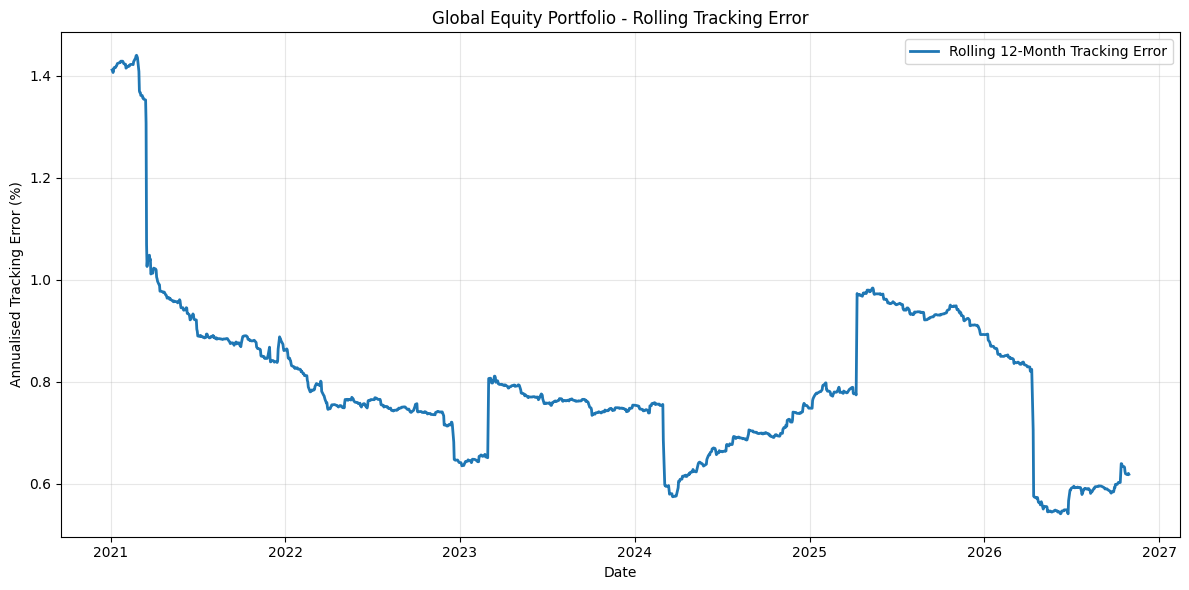

In [24]:

# ---------------------------------------------------------
# PHASE 3 - STEP 11: ROLLING TRACKING ERROR
# ---------------------------------------------------------

# Define the rolling window as 252 trading days.
# This represents approximately one trading year.

window = 252

# Calculate the standard deviation of active returns
# over the preceding 252 trading days.
#
# rolling(window) creates a moving window.
# std() calculates the standard deviation within it.

rolling_tracking_error = (
    performance["Active Return"]
    .rolling(window=window)
    .std(ddof=1)
    * np.sqrt(trading_days)
)

# Create a chart for rolling tracking error.

plt.figure(figsize=(12, 6))

# Multiply by 100 to express tracking error as a percentage.

plt.plot(
    rolling_tracking_error.index,
    rolling_tracking_error * 100,
    label="Rolling 12-Month Tracking Error",
    linewidth=2
)

plt.title("Global Equity Portfolio - Rolling Tracking Error")
plt.xlabel("Date")
plt.ylabel("Annualised Tracking Error (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

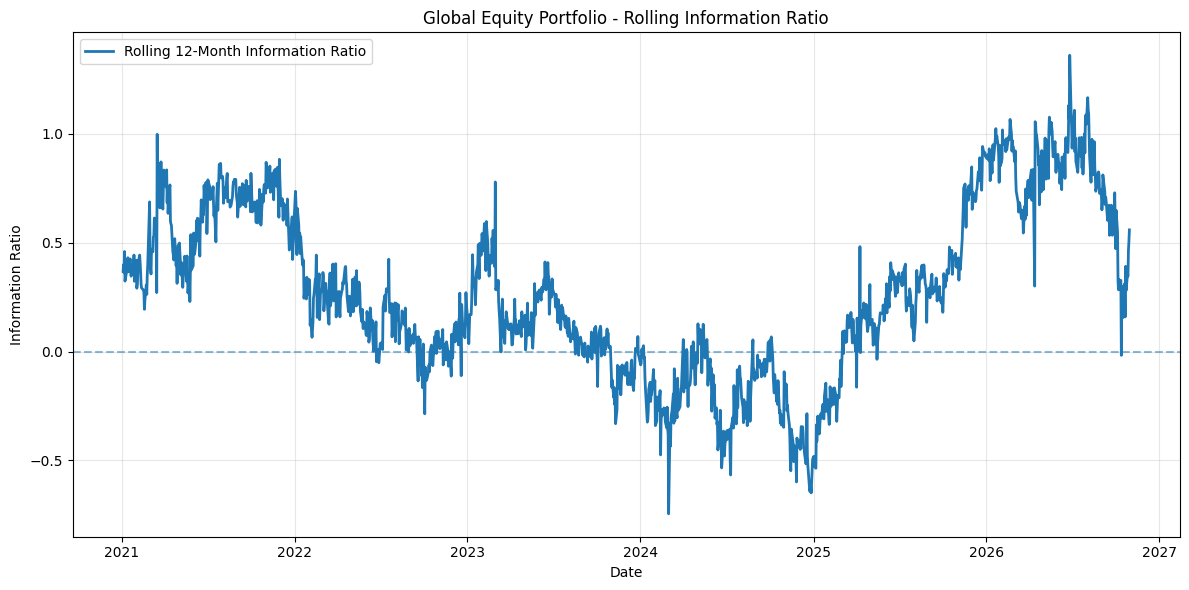

In [25]:

# ---------------------------------------------------------
# PHASE 3 - STEP 12: ROLLING INFORMATION RATIO
# ---------------------------------------------------------

# Calculate the average daily active return over
# each rolling 252-day window.
#
# Multiply by 252 to annualise the arithmetic mean.

rolling_active_return = (
    performance["Active Return"]
    .rolling(window=window)
    .mean()
    * trading_days
)

# Divide rolling annualised active return by
# rolling annualised tracking error.
#
# replace(0, np.nan) avoids division by zero
# if tracking error happens to equal zero.

rolling_information_ratio = (
    rolling_active_return
    / rolling_tracking_error.replace(0, np.nan)
)

# Visualise the rolling information ratio.

plt.figure(figsize=(12, 6))

plt.plot(
    rolling_information_ratio.index,
    rolling_information_ratio,
    label="Rolling 12-Month Information Ratio",
    linewidth=2
)

# Add a reference line at zero.
# Positive values indicate positive average active returns
# over the corresponding rolling window.

plt.axhline(0, linestyle="--", alpha=0.5)

plt.title("Global Equity Portfolio - Rolling Information Ratio")
plt.xlabel("Date")
plt.ylabel("Information Ratio")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:

# ---------------------------------------------------------
# PHASE 3 - STEP 13: EXPORT PERFORMANCE & RISK RESULTS
# ---------------------------------------------------------

# Save the performance scorecard as a CSV file.
#
# The index contains metric names, so index=True
# preserves those labels in the exported file.

scorecard.to_csv(
    "performance_risk_scorecard.csv",
    index=True
)

# Combine rolling metrics into a single DataFrame.
#
# Each column represents a historical risk metric.

rolling_metrics = pd.DataFrame({
    "Rolling Volatility - Portfolio":
        rolling_volatility["Portfolio"],
    "Rolling Volatility - Benchmark":
        rolling_volatility["Benchmark"],
    "Rolling Tracking Error":
        rolling_tracking_error,
    "Rolling Information Ratio":
        rolling_information_ratio
})

# Export the rolling metrics as a separate CSV file.

rolling_metrics.to_csv(
    "rolling_risk_metrics.csv",
    index=True
)

print("Performance and risk files saved successfully.")

Performance and risk files saved successfully.
